# Insurance Risk Project

## Imports

In [2]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
from plotly import graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## Data Source

In [3]:
# descargar desde kagglehub
file_path = "train.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "ifteshanajnin/carinsuranceclaimprediction-classification",
  file_path,
)


In [4]:
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


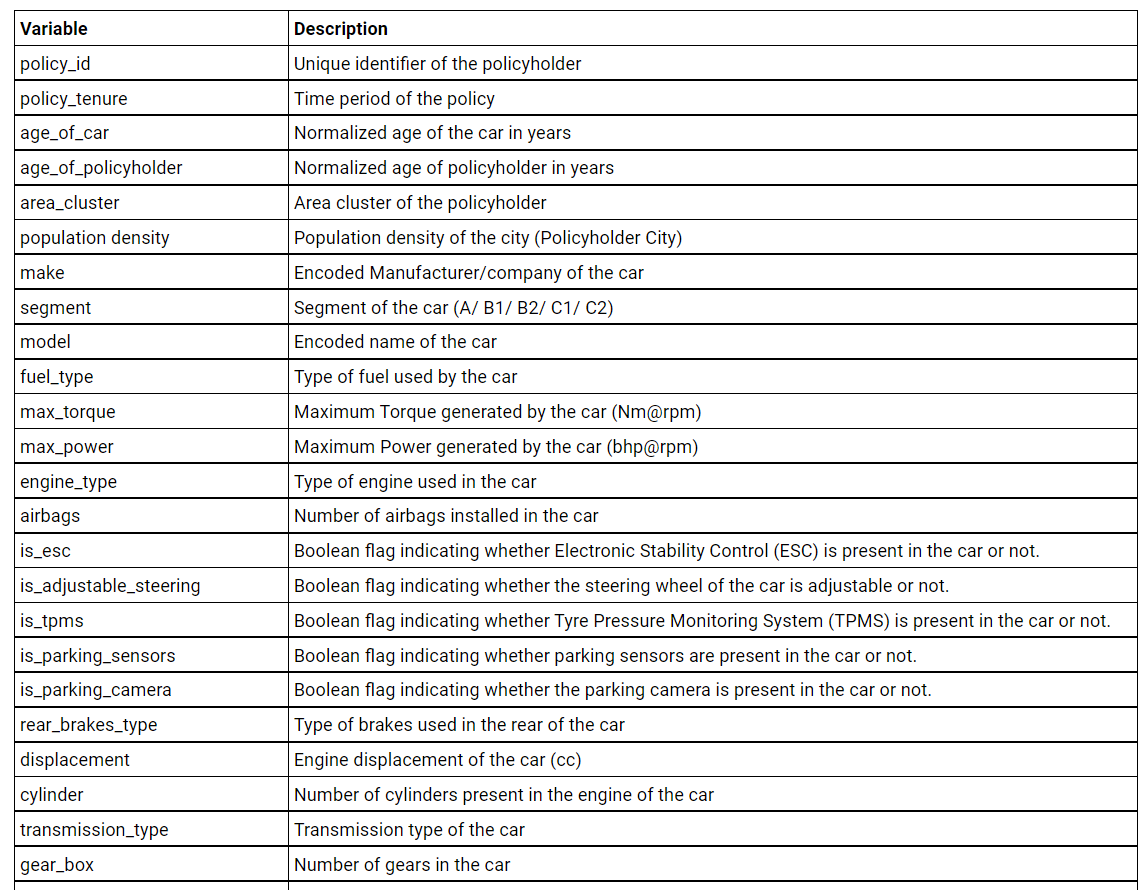

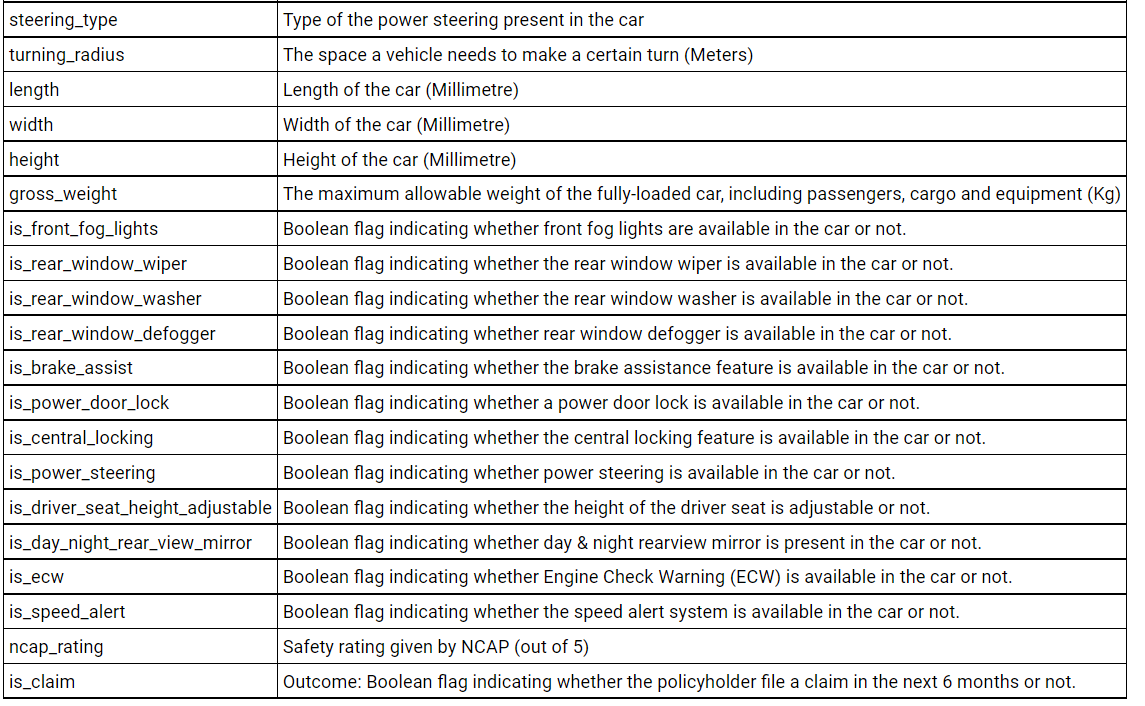

In [5]:
# esquema
from IPython.display import Image, display

display(Image("../external_info/schema.png"))
display(Image("../external_info/schema_2.png"))

## EDA

In [6]:
# número de columnas y filas
print(f"{len(df.columns)} columnas en dataset")
print(f"{len(df)} filas en dataset")

44 columnas en dataset
58592 filas en dataset


In [7]:
# vistazo de columnas, tipos de datos y nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 44 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  str    
 1   policy_tenure                     58592 non-null  float64
 2   age_of_car                        58592 non-null  float64
 3   age_of_policyholder               58592 non-null  float64
 4   area_cluster                      58592 non-null  str    
 5   population_density                58592 non-null  int64  
 6   make                              58592 non-null  int64  
 7   segment                           58592 non-null  str    
 8   model                             58592 non-null  str    
 9   fuel_type                         58592 non-null  str    
 10  max_torque                        58592 non-null  str    
 11  max_power                         58592 non-null  str    
 12  engine_type    

In [8]:
# nulos
df.isna().sum() / len(df)

policy_id                           0.0
policy_tenure                       0.0
age_of_car                          0.0
age_of_policyholder                 0.0
area_cluster                        0.0
population_density                  0.0
make                                0.0
segment                             0.0
model                               0.0
fuel_type                           0.0
max_torque                          0.0
max_power                           0.0
engine_type                         0.0
airbags                             0.0
is_esc                              0.0
is_adjustable_steering              0.0
is_tpms                             0.0
is_parking_sensors                  0.0
is_parking_camera                   0.0
rear_brakes_type                    0.0
displacement                        0.0
cylinder                            0.0
transmission_type                   0.0
gear_box                            0.0
steering_type                       0.0


In [9]:
# presencia de strings vacios o nulos
for col in df:
    mask_emty = (df[col]=='') | (df[col]==' ') 
    mask_nul_str = (df[col]=='nan') | (df[col]=='NAN') | (df[col]=='NULL') | (df[col]=='null') 
    if len (df[mask_emty]) > 0:
        print(f" columna {col} contiene {len (df[mask_emty])} con strings vacíos")
    if len (df[mask_nul_str]) > 0:
            print(f" columna {col} contiene {len (df[mask_nul_str])} con strings indicando valores nulos")



In [10]:
# balanceo de clases
balance = df['is_claim'].value_counts(normalize = True)

fig_pay = go.Figure()
fig_pay.add_trace(go.Pie(
    labels=balance.index,
    values=balance.values,
    pull=[0,0.1]
))

fig_pay.update_layout(title= 'Balanceo de Clases')
fig_pay.show()

print(df['is_claim'].value_counts())


is_claim
0    54844
1     3748
Name: count, dtype: int64


In [11]:
# estadistica descriptiva columnas númericas
# age_of_car, age_of_policyholder, policy_tenure normalizadas?
df.describe()

,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,turning_radius,length,width,height,gross_weight,ncap_rating,is_claim
count,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.00000,58592.000000,58592.000000,58592.000000
mean,0.611246,0.069424,0.469420,18826.858667,1.763722,3.137066,1162.355851,3.626963,5.245443,4.852893,3850.476891,1672.233667,1553.33537,1385.276813,1.759950,0.063968
std,0.414156,0.056721,0.122886,17660.174792,1.136988,1.832641,266.304786,0.483616,0.430353,0.228061,311.457119,112.089135,79.62227,212.423085,1.389576,0.244698
min,0.002735,0.000000,0.288462,290.000000,1.000000,1.000000,796.000000,3.000000,5.000000,4.500000,3445.000000,1475.000000,1475.00000,1051.000000,0.000000,0.000000
25%,0.210250,0.020000,0.365385,6112.000000,1.000000,2.000000,796.000000,3.000000,5.000000,4.600000,3445.000000,1515.000000,1475.00000,1185.000000,0.000000,0.000000
50%,0.573792,0.060000,0.451923,8794.000000,1.000000,2.000000,1197.000000,4.000000,5.000000,4.800000,3845.000000,1735.000000,1530.00000,1335.000000,2.000000,0.000000
75%,1.039104,0.110000,0.548077,27003.000000,3.000000,6.000000,1493.000000,4.000000,5.000000,5.000000,3995.000000,1755.000000,1635.00000,1510.000000,3.000000,0.000000
max,1.396641,1.000000,1.000000,73430.000000,5.000000,6.000000,1498.000000,4.000000,6.000000,5.200000,4300.000000,1811.000000,1825.00000,1720.000000,5.000000,1.000000


In [12]:
# conteos y frecuencias de columnas tipo str
df.describe(include='str')

,policy_id,area_cluster,segment,model,fuel_type,max_torque,max_power,engine_type,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,transmission_type,steering_type,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert
count,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592,58592
unique,58592,22,6,11,3,9,9,11,2,2,2,2,2,2,2,3,2,2,2,2,2,2,2,2,2,2,2,2
top,ID00001,C8,B2,M1,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,F8D Petrol Engine,No,Yes,No,Yes,No,Drum,Manual,Power,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes
freq,1,13654,18314,14948,20532,17796,17796,14948,40191,35526,44574,56219,35704,44574,38181,33502,33928,41634,41634,38077,32177,42435,42435,57383,34291,36309,42435,58229


In [13]:
# duplicados
df['policy_id'].duplicated().sum()

np.int64(0)

In [14]:
# columnas con mayor cardinalidad (area cluster con 22)
cardinality = df.select_dtypes('str').nunique().reset_index()
cardinality = cardinality.rename(columns = {'index':'column',
                                            0:'nunique'})

cardinality.sort_values(by='nunique', ascending=False).head(5)

,column,nunique
0,policy_id,58592
1,area_cluster,22
3,model,11
7,engine_type,11
5,max_torque,9


In [15]:
# histogramas de columnas numéricas
numeric_cols = df.select_dtypes(include=np.number).columns.drop(['is_claim', 'make'])

n_cols = 4
n_rows = -(-len(numeric_cols) // n_cols)  # ceil division

fig = make_subplots(rows=n_rows, cols=n_cols, subplot_titles=numeric_cols)

for i, col in enumerate(numeric_cols):
    row = i // n_cols + 1
    col_pos = i % n_cols + 1
    fig.add_trace(go.Histogram(x=df[col], name=col, showlegend=False), row=row, col=col_pos)

fig.update_layout(height=250 * n_rows, title_text="Distribución de columnas numéricas")
fig.show()

In [16]:
# bar charts de claims por columna agrupada
columns = ['segment', 'model', 'fuel_type', 'engine_type', 'airbags', 'cylinder', 'gear_box']

n_cols = 4
n_rows = -(-len(columns) // n_cols)  # ceil division

fig = make_subplots(rows=n_rows, cols=n_cols, subplot_titles=columns)

for i, col in enumerate(columns):
    grouped = df.groupby(col).agg(claim_rate=('is_claim', 'mean')).reset_index()
    row = i // n_cols + 1
    col_pos = i % n_cols + 1
    fig.add_trace(go.Bar(x=grouped[col], y=grouped['claim_rate'], name=col, showlegend=False), row=row, col=col_pos)

fig.update_layout(height=300 * n_rows, title_text="Claim Rate por columna")
fig.show()

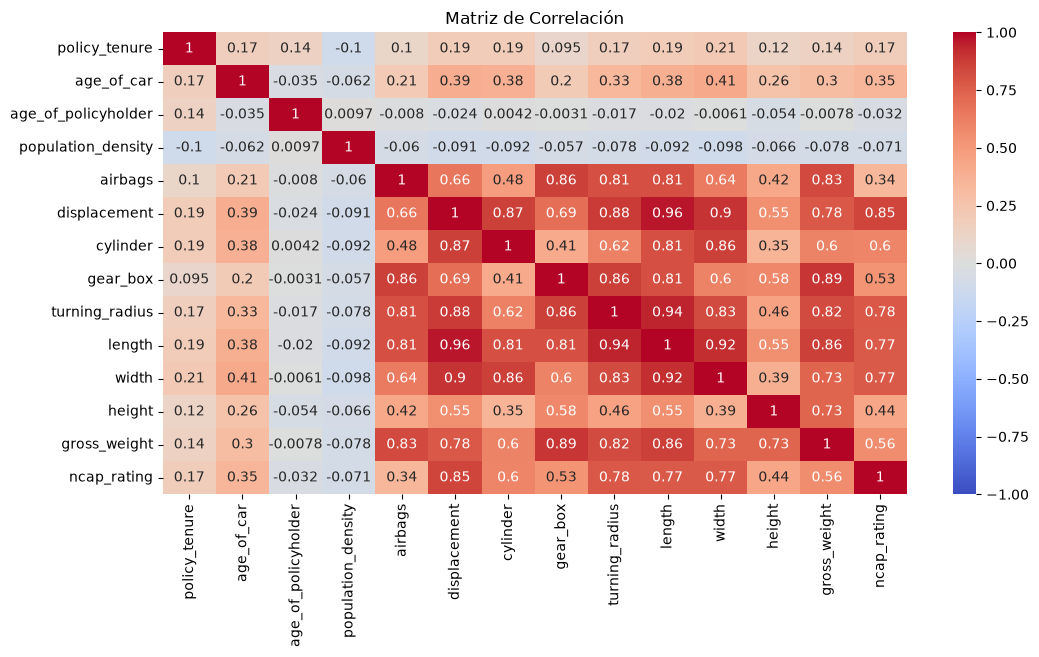

In [17]:
# correlacion entre variables
plt.figure(figsize=(12, 6))

correlation = df[numeric_cols].corr()
heatmap = sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de Correlación")
plt.show()

In [18]:
# pares de variables con correlación fuerte (|r| > 0.6)
# triángulo superior para no duplicar pares (A-B == B-A) ni incluir la diagonal (autocorrelación = 1)
mask = np.triu(np.ones(correlation.shape), k=1).astype(bool)

corr_pairs = correlation.where(mask).stack()
corr_pairs = corr_pairs[corr_pairs.abs() > 0.6].sort_values(ascending=False)

corr_pairs = corr_pairs.reset_index()
corr_pairs.columns = ['var_1', 'var_2', 'correlation']
corr_pairs

,var_1,var_2,correlation
0,displacement,length,0.961655
1,turning_radius,length,0.944899
2,length,width,0.915918
3,displacement,width,0.899302
4,gear_box,gross_weight,0.894639
5,displacement,turning_radius,0.875407
6,displacement,cylinder,0.866231
7,cylinder,width,0.862430
8,gear_box,turning_radius,0.861740
9,length,gross_weight,0.861723


In [19]:
# podemos descartar las siguientes columnas por colinearidad 
# de las columnas relacionadas a las especificaciones del auto, nos quedamos con gross_weight y ncap_rating

df = df.drop(
    columns=[
        'airbags',
        'displacement',
        'cylinder',
        'gear_box',
        'turning_radius',
        'length',
        'width',
        'height',
    ]
)

In [20]:
6//2

3

In [21]:
# outliers (deteccion con boxplot)
numeric_cols = df.select_dtypes(include=np.number).columns.drop(['is_claim', 'make'])

n_cols = 2
n_rows = (len(numeric_cols) // n_cols)  # ceil division

fig = make_subplots(rows=n_rows, cols=n_cols, subplot_titles=numeric_cols)

for i, col in enumerate(numeric_cols):
    row = i // n_cols + 1
    col_pos = i % n_cols + 1
    fig.add_trace(go.Box(y=df[col], name=col), row=row, col=col_pos)

fig.update_layout(height=250 * n_rows, title_text="Box plots")
fig.show()

In [82]:
# extra: celda extra para comprobar hipotesis de shap en notebook de modelado
# polizas con menor duracion tienen menor siniestralidad?
# polizas de autos mas nuevos tienen mayor siniestralidad?

def tasa_por_rango(df, col, target='is_claim', bins=10):
    # qcut: grupos con la MISMA cantidad de pólizas (no el mismo ancho)
    grupos = pd.qcut(df[col], q=bins, duplicates='drop')
    resumen = df.groupby(grupos, observed=True)[target].agg(['mean', 'count'])
    
    return resumen


numeric_cols = ['policy_tenure', 'age_of_car']

n_cols = 1
n_rows = 2

fig = make_subplots(rows=n_rows, cols=n_cols, subplot_titles=numeric_cols)

for i, col in enumerate(numeric_cols):
    row = i // n_cols + 1
    col_pos = i % n_cols + 1
    
    resumen = tasa_por_rango(df, col)
    
    x=list(resumen.index.astype(str))
    y = np.repeat(df['is_claim'].mean(), len(x))
    fig.add_trace(go.Bar(x=x, y=resumen['mean'], name='claim_rate'),row=row, col=col_pos)
    fig.add_trace(go.Scatter(x= x,y=y, name='claim_rate_average'), row=row, col=col_pos)
    
    

fig.update_layout(height=500 * n_rows, title_text="Shap Test")
fig.show()

## Conclusiones EDA
- Forma de dataset: 44 columnas en dataset con 58592 filas 
- Presencia de records invalidos: no parece haber registros nulos, tampoco registros con strings vacios o que indiquen un record nulo en texto
- Duplicados: tampoco existen duplicados de número de póliza, ningun record comparte los mismos valores de las columnas
- Balanceo de clases: Existe un desbalance fuerte en las clases aunque natural en este tipo de industria, tan solo el 6.4% de los records son identificados como siniestros
- Cardinalidad en columnas categoricas: las columnas categoricas con mayor cantidad de registros únicos son.  
Lo que significaría tener cuidado en el preprocesamiento y no intentar one hot encoders en algunas de ellas
    1. area_cluster	22.  
    2. model	11.  
    3. engine_type	11.  
    4. max_torque	9.  
- Distribución de columnas númericas: parece ser que age of car y age of policyholder estan ya normalizadas, se observan outliers en columnas como:
    - age_of_policyholder
    - population_density (tal vez valga la pena aplicar algun scaling)
    - age_of_car
- Correlación entre variables: Se propone solo trabajar con dos variables referentes a las especificaciones del auto, gross_weight y ncap_rating ya que todas las demás presentan importante colinearidad
- Formato de columnas: max_torque y max_power vienen como texto (ej. "60Nm@3500rpm", "40.36bhp@6000rpm"), combinando valor, unidad y rpm en un solo string. Van a necesitar parseo a numérico antes de poder usarse en el modelo